In [1]:

!pip install -q tensorflow-datasets scikit-image opencv-python


In [3]:
!pip install -q importlib_resources

import tensorflow_datasets as tfds

dataset, info = tfds.load(
    'cats_vs_dogs',
    split='train',
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", info.splits['train'].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.QZAWAT_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Total images: 23262


In [4]:

import cv2
import numpy as np
from skimage.feature import hog
from tqdm import tqdm

X = []
y = []

count = {0: 0, 1: 0}
limit = 1000

for image, label in tqdm(dataset):
    label = int(label.numpy())

    if count[label] >= limit:
        continue

    image = image.numpy()
    image = cv2.resize(image, (64, 64))
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    features = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2)
    )

    X.append(features)
    y.append(label)
    count[label] += 1

    if count[0] >= limit and count[1] >= limit:
        break

X = np.array(X)
y = np.array(y)

print("Images:", len(X))
print("Features:", X.shape)
print("Labels:", np.unique(y, return_counts=True))


  9%|▉         | 2038/23262 [00:14<02:31, 139.68it/s]

Images: 2000
Features: (2000, 1764)
Labels: (array([0, 1]), array([1000, 1000]))


Accuracy: 70.25 %

Classification Report:
              precision    recall  f1-score   support

         Cat       0.68      0.75      0.72       200
         Dog       0.72      0.66      0.69       200

    accuracy                           0.70       400
   macro avg       0.70      0.70      0.70       400
weighted avg       0.70      0.70      0.70       400



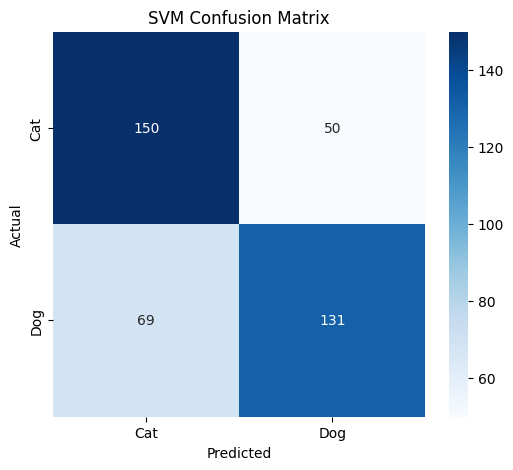

In [5]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

svm = SVC(kernel='rbf', C=10, gamma='scale')

svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Cat', 'Dog']))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cat', 'Dog'],
            yticklabels=['Cat', 'Dog'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()


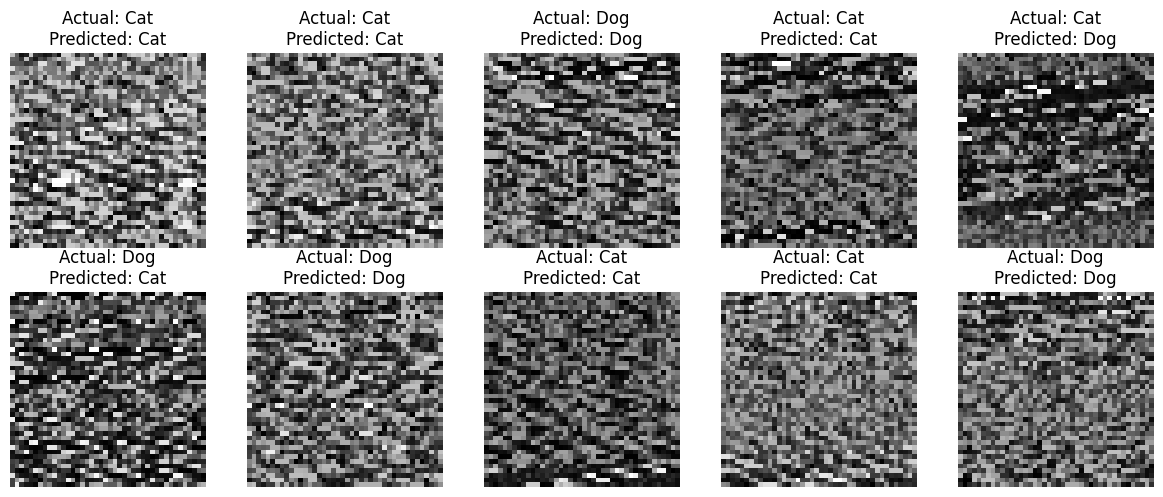

In [6]:

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    actual = 'Cat' if y_test[i] == 0 else 'Dog'
    predicted = 'Cat' if y_pred[i] == 0 else 'Dog'

    plt.imshow(X[i].reshape(42, 42), cmap='gray')
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()
